# 05. 다운샘플링 실험 — 셀별 실행

스크립트(`05_sampling_*.py`)의 함수를 그대로 부른다. 코드 수정은 `.py` 에서 하고 여기선 실행·확인만.
긴 실험(여러 조건)은 노트북보다 터미널 `nohup` 이 안전하다 — 이 노트북은 **조건 1~2개를 돌려보며 결과를 눈으로 보는 용도**.

```
select → audit (통계) → train (조건별) → collect (합쳐서 비교)
```

실험 조건 = select(방식×비율) × apply(loss|struct) × reweight(ipw|none) × pi_eff × seed
- apply=loss : 그래프 유지, loss 에 넣는 정상 target 만 줄임 (지도 샘플링)
- apply=struct : adjacency 에서도 제거 (구조 샘플링)
- reweight=ipw : 선택 정상에 모집단/선택 가중치 (full 손실의 불편추정)  /  none : 가중치 1
- pi_eff : 손실에서 양성 가중치 비중. pos_weight 를 여기서 역산해 r 과 분리

## 0. 설정

In [9]:
!pip install --break-system-packages --no-cache-dir -q torch_geometric

In [1]:
import importlib, json, time, sys
from pathlib import Path
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

import sampling_lib as L
select  = importlib.import_module("05_sampling_select")
audit   = importlib.import_module("05_sampling_audit")
train   = importlib.import_module("05_sampling_train")
collect = importlib.import_module("05_sampling_collect")

THREADS, MEMORY = 8, "12GB"          # cgroup 한도 27GB — DuckDB 한도 + 파이썬 배열이 그 안에 들어야 함
TRAIN = "2022-08-08:2022-09-27"      # 학습 구간 (태훈님 분할)
VAL   = "2022-09-28:2022-10-14"      # 검증 구간
print("ROOT", L.ROOT); print("BASE", L.BASE); print("출력", L.SAMPLING)
for f in ["transactions.parquet", "patterns.parquet", "features/edge_features.parquet", "features/node_features.parquet"]:
    print(f"{'OK ' if (L.BASE/f).is_file() else '없음'} {f}")

ROOT /workspace/money_laundry_ai_
BASE /workspace/money_laundry_ai_/parquets/HI-Large
출력 /workspace/money_laundry_ai_/parquets/HI-Large/sampling
OK  transactions.parquet
OK  patterns.parquet
OK  features/edge_features.parquet
OK  features/node_features.parquet


### 학습 구간 라벨 분포 — 일별 양성 수와 정상 수 (r 범위 정하는 근거)

In [2]:
con = L.connect(THREADS, MEMORY)
lab = L.load_labels(con, L.parse_window(TRAIN))
daily = lab.groupby("day").agg(pos=("y", "sum"), n=("y", "size"), unmatched=("in_pattern", lambda s: int(((lab.loc[s.index, "y"] == 1) & ~s).sum())))
daily["neg"] = daily.n - daily.pos; daily["neg_per_pos"] = (daily.neg / daily.pos).round(0)
print(f"학습 구간 {len(lab):,}건, 양성 {int(lab.y.sum()):,} (패턴 외 {int(daily.unmatched.sum()):,}), 정상 {int((lab.y==0).sum()):,}")
print(f"정상:양성 전체 = 1:{(lab.y==0).sum()/lab.y.sum():.0f}")
daily[["pos", "unmatched", "neg", "neg_per_pos"]].describe().round(0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

학습 구간 91,432,129건, 양성 98,932 (패턴 외 43,095), 정상 91,333,197
정상:양성 전체 = 1:923


,pos,unmatched,neg,neg_per_pos
count,51.0,51.0,51.0,51.0
mean,1940.0,845.0,1790847.0,946.0
std,363.0,108.0,735124.0,407.0
min,1190.0,623.0,826600.0,377.0
25%,1674.0,788.0,830324.0,642.0
50%,2078.0,853.0,1927594.0,868.0
75%,2274.0,936.0,1928747.0,1197.0
max,2384.0,1029.0,4288843.0,2024.0


## 1. 선택 (select) — 방식 × 비율

`select/<method>_r<ratio>/selected.parquet` 가 만들어진다. 이미 있으면 건너뜀.
`none` 은 샘플링 없음(기준선), 양성은 항상 전부 포함.

In [3]:
select.main(["--method", "none",   "--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY])
select.main(["--method", "random", "--ratio", "10", "--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY])
# select.main(["--method", "random", "--ratio", "100", "--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY])
# select.main(["--method", "hard",   "--ratio", "10", "--hard-frac", "0.5", "--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY])
# select.main(["--method", "cssmc",  "--ratio", "10", "--clusters", "30", "--candidates", "10", "--train", TRAIN, "--threads", str(THREADS), "--memory", MEMORY])

[03:26:11] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/none
[03:26:11] 이미 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/select/random_r10


### 선택 결과 확인 — 일별 양성/정상 수, IPW

In [4]:
name = "random_r10"
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet")
print(json.dumps(json.loads((L.SAMPLING / "select" / name / "meta.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=1))
sel.groupby("day").agg(pos=("y", "sum"), neg=("y", lambda s: int((s == 0).sum())), ipw_neg=("ipw", lambda s: float(s[sel.loc[s.index, "y"] == 0].mean()))).head(10)

{
 "method": "random",
 "ratio": 10.0,
 "train": "2022-08-08:2022-09-25",
 "seed": 42,
 "hard_frac": 0.5,
 "clusters": 30,
 "candidates": 10,
 "rows": 1037399,
 "pos": 94309,
 "neg": 943090,
 "neg_population": 87477917,
 "ipw_sum_neg": 87477917.0,
 "daily_keep_min": 0.0049407264383424625,
 "daily_keep_max": 0.026520466567335466,
 "seconds": 36.0
}


,pos,neg,ipw_neg
day,,,
2022-08-08,1190,11900,161.948067
2022-08-09,1227,12270,157.098126
2022-08-10,1300,13000,148.178923
2022-08-11,1349,13490,142.905263
2022-08-12,1410,14100,185.836028
2022-08-13,1278,12780,64.838967
2022-08-14,1305,13050,63.543678
2022-08-15,1519,15190,126.885319
2022-08-16,1594,15940,120.988896


## 2. 감사 (audit) — 학습 없이 통계로 비교

피처는 `edge_features.parquet` 에서 DuckDB 로 읽는다 (memmap 캐시 불필요). 선택 하나당 parquet 스캔 2회 + 집계 → 수 분.

In [5]:
audit.main(["--all", "--threads", str(THREADS), "--memory", MEMORY])

[03:26:12] 감사 있음: none


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[03:26:58] random_r10: KL raw 0.00404 / ipw 0.00001, 일별보존 5.37배, hard 0.231→0.233, 양성1홉보존 0.015


In [6]:
import glob
A = pd.DataFrame({Path(p).parent.name: json.loads(open(p, encoding="utf-8").read()) for p in glob.glob(str(L.SAMPLING / "select" / "*" / "audit.json"))}).T
A["kl_raw"] = A.feature_raw.map(lambda d: d["kl_mean"]); A["kl_ipw"] = A.feature_ipw.map(lambda d: d["kl_mean"]); A["kl_max_feature"] = A.feature_raw.map(lambda d: d["kl_max_feature"])
A[["method", "ratio", "n_sel", "keep_rate", "kl_raw", "kl_ipw", "kl_max_feature", "daily_keep_ratio", "hour_jsd", "hard_frac_pop", "hard_frac_sel", "sibling_frac_pop", "sibling_frac_sel", "struct_pos_hop1_keep"]].round(5)

,method,ratio,n_sel,keep_rate,kl_raw,kl_ipw,kl_max_feature,daily_keep_ratio,hour_jsd,hard_frac_pop,hard_frac_sel,sibling_frac_pop,sibling_frac_sel,struct_pos_hop1_keep
none,none,None,87477917,1.0,0.00000,0.00000,NaN,1.0,0.0,0.230564,0.230564,0.004205,0.004205,1.0
random_r10,random,10.0,943090,0.010781,0.00404,0.00001,pair_history_count,5.367726,0.000084,0.230564,0.232618,0.004205,0.003737,0.01548


### 피처 분포 그림 — 모집단 vs 선택 정상 (KL 큰 피처 위주)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

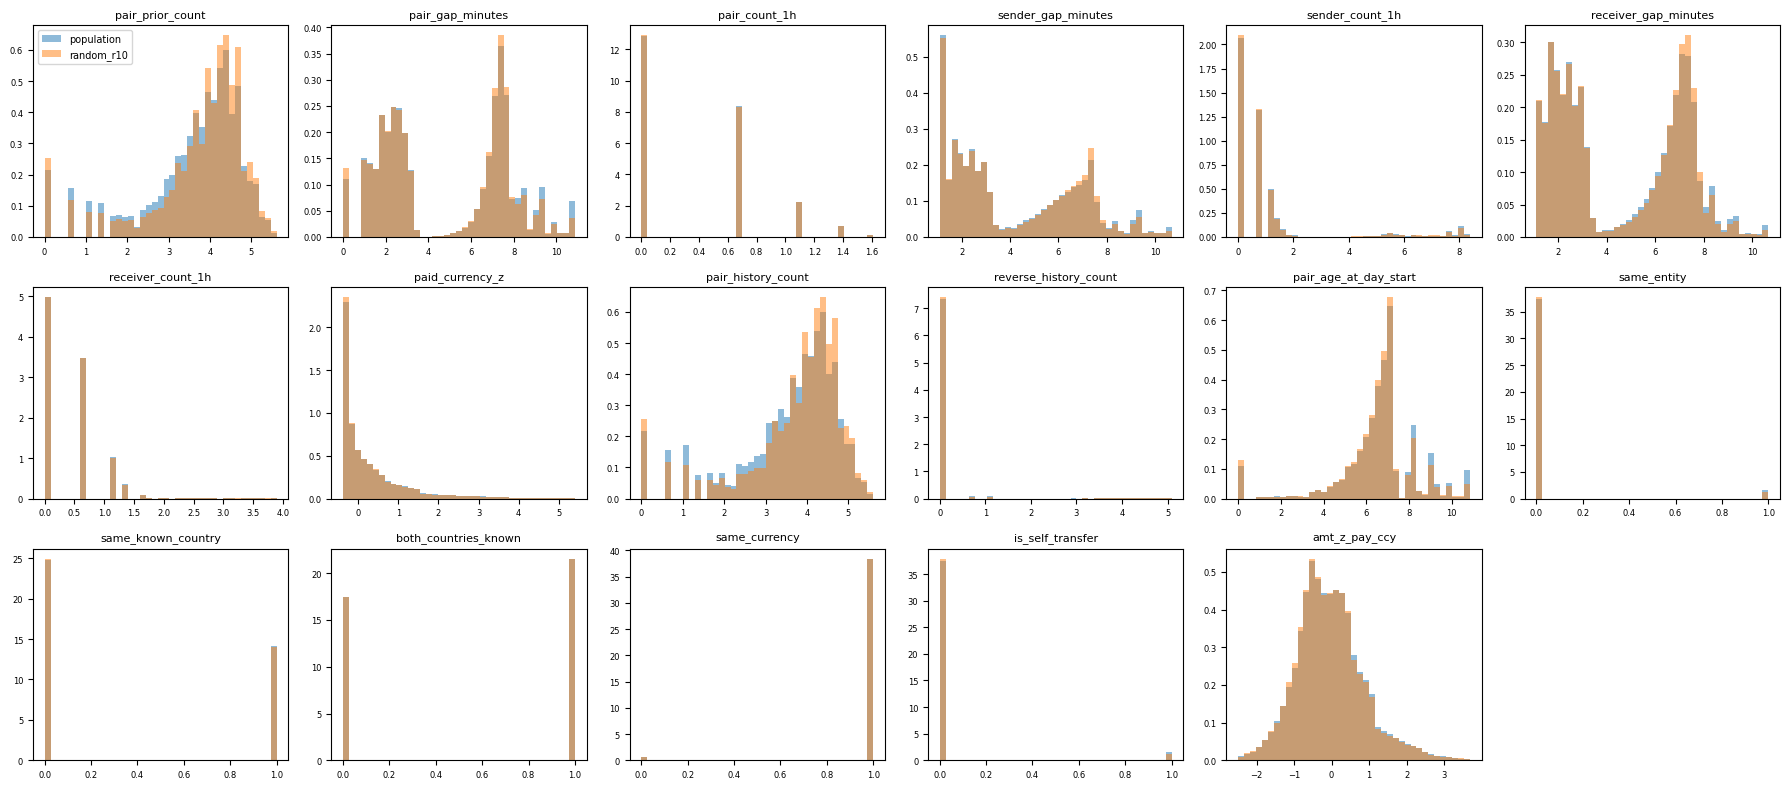

In [7]:
import matplotlib.pyplot as plt
name = "random_r10"
feat_dir = L.features_dir("features")
sel = pd.read_parquet(L.SAMPLING / "select" / name / "selected.parquet"); smp = sel[sel.y == 0]
pop_ids = np.sort(np.random.default_rng(0).choice(lab[lab.y == 0].edge_id.to_numpy(), 300_000, replace=False))
Xp, Xs = audit.read_features(con, feat_dir, pop_ids), audit.read_features(con, feat_dir, np.sort(smp.edge_id.to_numpy()[np.random.default_rng(0).choice(len(smp), min(len(smp), 300_000), replace=False)]))
fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for j, ax in enumerate(axes.ravel()[:17]):
    lo, hi = np.quantile(Xp[:, j], [0.001, 0.999]); bins = np.linspace(lo, hi, 40)
    ax.hist(Xp[:, j], bins, density=True, alpha=.5, label="population"); ax.hist(Xs[:, j], bins, density=True, alpha=.5, label=name)
    ax.set_title(L.EDGE_FEATURES[j], fontsize=8); ax.tick_params(labelsize=6)
axes.ravel()[0].legend(fontsize=7); axes.ravel()[17].axis("off"); fig.tight_layout(); plt.show()

## 3. 학습 (train) — 조건 1개

처음 한 번은 `GraphStore` memmap 캐시(엣지 피처 1.8억×17 float32 ≈ 12GB + adjacency)를 만드느라 오래 걸린다. 그 다음부턴 바로.
처음엔 `--max-train-targets` 로 작게 돌려 **target당 시간·GPU 메모리**를 재고, 그걸로 r 상한을 정한다.
`run.json` 있으면 건너뛴다 (다시 돌리려면 `runs/<run_name>/` 삭제).

In [10]:
t0 = time.time()
train.main(["--select", "random_r10", "--apply", "loss", "--reweight", "none", "--pi-eff", "0.25", "--seed", "42",
            "--val", VAL, "--epochs", "1", "--max-train-targets", "5000", "--batch", "32",
            "--threads", str(THREADS), "--memory", MEMORY])
print(f"{(time.time()-t0)/60:.1f}분")

[03:32:11] random_r10_loss_none_pi0.25_s42: target 1,037,399 (양성 94,309, 정상 943,090), 정상 가중치 합 943,090, pos_weight=3.33
[03:32:11] GraphStore 캐시 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/cache/features
[03:34:14]   epoch 1 0/5,000 loss 0.9158
[04:03:22] epoch 1: {'AP': 0.0669672643474981, 'F1': 0.15633697362034493, 'precision': 0.10841676491065567, 'recall': 0.28017378145517563, 'threshold': 0.8118880391120911, 'recall_at_1pct': 0.5221742207903151, 'unmatched_recall_at_1pct': 0.2833263435384339, 'ECE': 0.027147648003111684}
[04:03:22] 끝: random_r10_loss_none_pi0.25_s42 best AP 0.0670 (31.2분)
31.2분


In [11]:
run = "random_r10_loss_none_pi0.25_s42"
r = json.loads((L.SAMPLING / "runs" / run / "run.json").read_text(encoding="utf-8"))
print(f"target당 {r['train_sec_per_epoch'] / min(5000, r['train_rows']) * 1000:.1f} ms  (epoch {r['train_sec_per_epoch']:.0f}s / GPU peak {r['gpu_peak_gb']} GB)")
print("검증:", {k: round(v, 4) for k, v in r["val"].items()})
pd.read_csv(L.SAMPLING / "runs" / run / "history.csv")

target당 373.2 ms  (epoch 1866s / GPU peak 2.169700352 GB)
검증: {'AP': 0.067, 'F1': 0.1563, 'precision': 0.1084, 'recall': 0.2802, 'threshold': 0.8119, 'recall_at_1pct': 0.5222, 'unmatched_recall_at_1pct': 0.2833, 'ECE': 0.0271}


,epoch,train_loss,train_sec,AP,F1,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE
0,1,0.352769,1866,0.066967,0.156337,0.108417,0.280174,0.811888,0.522174,0.283326,0.027148


### 검증 점수 분포 — 양성/정상 점수 히스토그램, 임계값

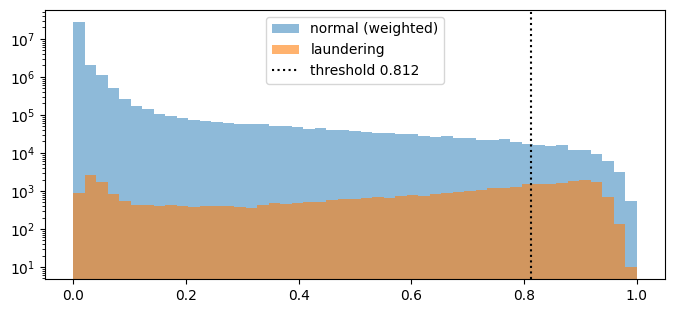

In [12]:
vs = pd.read_parquet(L.SAMPLING / "runs" / run / "val_scores.parquet")
fig, ax = plt.subplots(figsize=(8, 3.5)); bins = np.linspace(0, 1, 50)
ax.hist(vs[vs.y == 0].score, bins, weights=vs[vs.y == 0].w, alpha=.5, label="normal (weighted)", log=True)
ax.hist(vs[vs.y == 1].score, bins, alpha=.6, label="laundering", log=True)
ax.axvline(r["val"]["threshold"], color="k", ls=":", label=f"threshold {r['val']['threshold']:.3f}"); ax.legend(); plt.show()

### 본 실험 — 조건 여러 개

여기서 돌려도 되지만 수 시간 단위라 터미널 `nohup` 권장 (`run_grid.sh` 참고). 아래는 같은 명령을 노트북에서 부르는 형태.

In [13]:
GRID = [  # (select, apply, reweight, pi_eff, seed)
    # ("none",       "loss", "none", 0.25, 42),
    ("random_r10", "loss", "none", 0.25, 42),
    ("random_r10", "loss", "ipw",  0.25, 42),
    # ("random_r10", "struct", "none", 0.25, 42),
]
for s, ap_, rw, pi, seed in GRID:
    train.main(["--select", s, "--apply", ap_, "--reweight", rw, "--pi-eff", str(pi), "--seed", str(seed),
                "--val", VAL, "--epochs", "5", "--batch", "32", "--threads", str(THREADS), "--memory", MEMORY])

[04:04:17] none_loss_none_pi0.25_s42: target 87,572,226 (양성 94,309, 정상 87,477,917), 정상 가중치 합 87,477,917, pos_weight=309.19
[04:04:17] GraphStore 캐시 있음: /workspace/money_laundry_ai_/parquets/HI-Large/sampling/cache/features
[04:05:15]   epoch 1 0/87,572,226 loss 0.8693
[04:06:35]   epoch 1 6,400/87,572,226 loss 10.4527
[04:06:54]   epoch 1 12,800/87,572,226 loss 6.3741
[04:07:12]   epoch 1 19,200/87,572,226 loss 2.2902
[04:07:30]   epoch 1 25,600/87,572,226 loss 3.8652
[04:07:49]   epoch 1 32,000/87,572,226 loss 2.5362
[04:08:07]   epoch 1 38,400/87,572,226 loss 2.1541
[04:08:26]   epoch 1 44,800/87,572,226 loss 1.7216
[04:08:45]   epoch 1 51,200/87,572,226 loss 2.0183
[04:09:04]   epoch 1 57,600/87,572,226 loss 2.7498
[04:09:22]   epoch 1 64,000/87,572,226 loss 0.7488
[04:09:41]   epoch 1 70,400/87,572,226 loss 1.6935
[04:09:59]   epoch 1 76,800/87,572,226 loss 1.7157
[04:10:18]   epoch 1 83,200/87,572,226 loss 1.7917
[04:10:36]   epoch 1 89,600/87,572,226 loss 2.6146
[04:10:55]   epoc

KeyboardInterrupt: 

## 4. 합치기 (collect) — 통계 감사 + 모델 지표 한 표

In [ ]:
df, summ = collect.main()
df[["run_name", "method", "ratio", "apply", "reweight", "pi_eff", "pos_weight", "train_rows", "AP", "F1", "recall_at_1pct", "unmatched_recall_at_1pct", "ECE",
    "kl_raw", "daily_keep_ratio", "hard_frac_sel", "train_sec_per_epoch", "gpu_peak_gb"]].sort_values(["method", "ratio", "apply", "reweight"]).round(4) if df is not None else None

## 판단 기준 (메모)

1. audit 에서 `daily_keep_ratio` 가 수 배, `kl_raw` 가 random 보다 확 크면 학습 전에 탈락
2. `none`(샘플링 없음) 기준선 대비 AP 가 1 std 안에 드는 **가장 작은 r** — 비용이 목적
3. 같은 r·pi_eff 에서 cssmc/hard 가 random 을 이기는지 → 이기면 kl 또는 hard_frac 중 어느 쪽이 설명하는지
4. pi_eff 를 바꾼 조건은 ECE·threshold 도 같이 (확률이 밀림)
5. 시드 1개 결과에서 AP 차이 ±0.01 은 "차이 없음" (태훈님 시드 표준편차 0.005~0.016)